# 02 - Exploratory Data Analysis

Comprehensive EDA of the King County House Sales dataset including distributions, correlations, geographic patterns, and price per sqft analysis.

In [1]:
# Setup
import sys
sys.path.append('../')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from src.data.ingestion import load_raw_data
from src.utils.visualization import (
    setup_plotting_style,
    plot_distribution,
    plot_correlation_heatmap,
    plot_target_vs_feature,
    plot_price_geographic,
    plot_price_trends,
    plot_categorical_analysis,
    create_eda_dashboard
)
from src.config import DATA_RAW, REPORTS_DIR

In [2]:
# Load data
df = load_raw_data()
print(f"Loaded {df.shape[0]} rows, {df.shape[1]} columns")
setup_plotting_style()

Loading data from: /Users/premkumarreddy/projects/real estate/notebooks/../data/raw/kc_house_data.csv
Loaded 21613 rows, 21 columns
Loaded 21613 rows, 21 columns


=== 1. Target Distribution ===


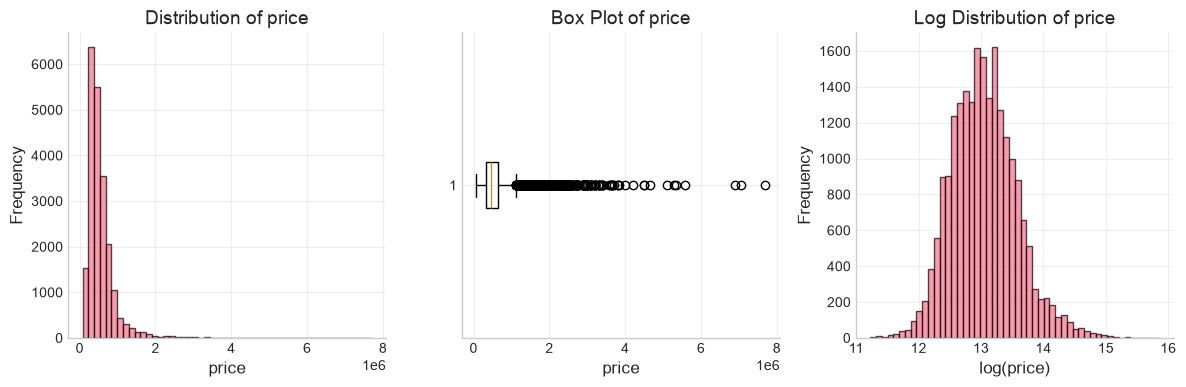

Log-price skew: 0.428
Log-price kurtosis: 0.692


In [3]:
# 1. Target Distribution
print("=== 1. Target Distribution ===")
fig = plot_distribution(df, 'price', log_scale=True)
plt.show()

# Log price stats
log_price = np.log1p(df['price'])
print(f"Log-price skew: {log_price.skew():.3f}")
print(f"Log-price kurtosis: {log_price.kurtosis():.3f}")

=== 2. Key Feature Distributions ===


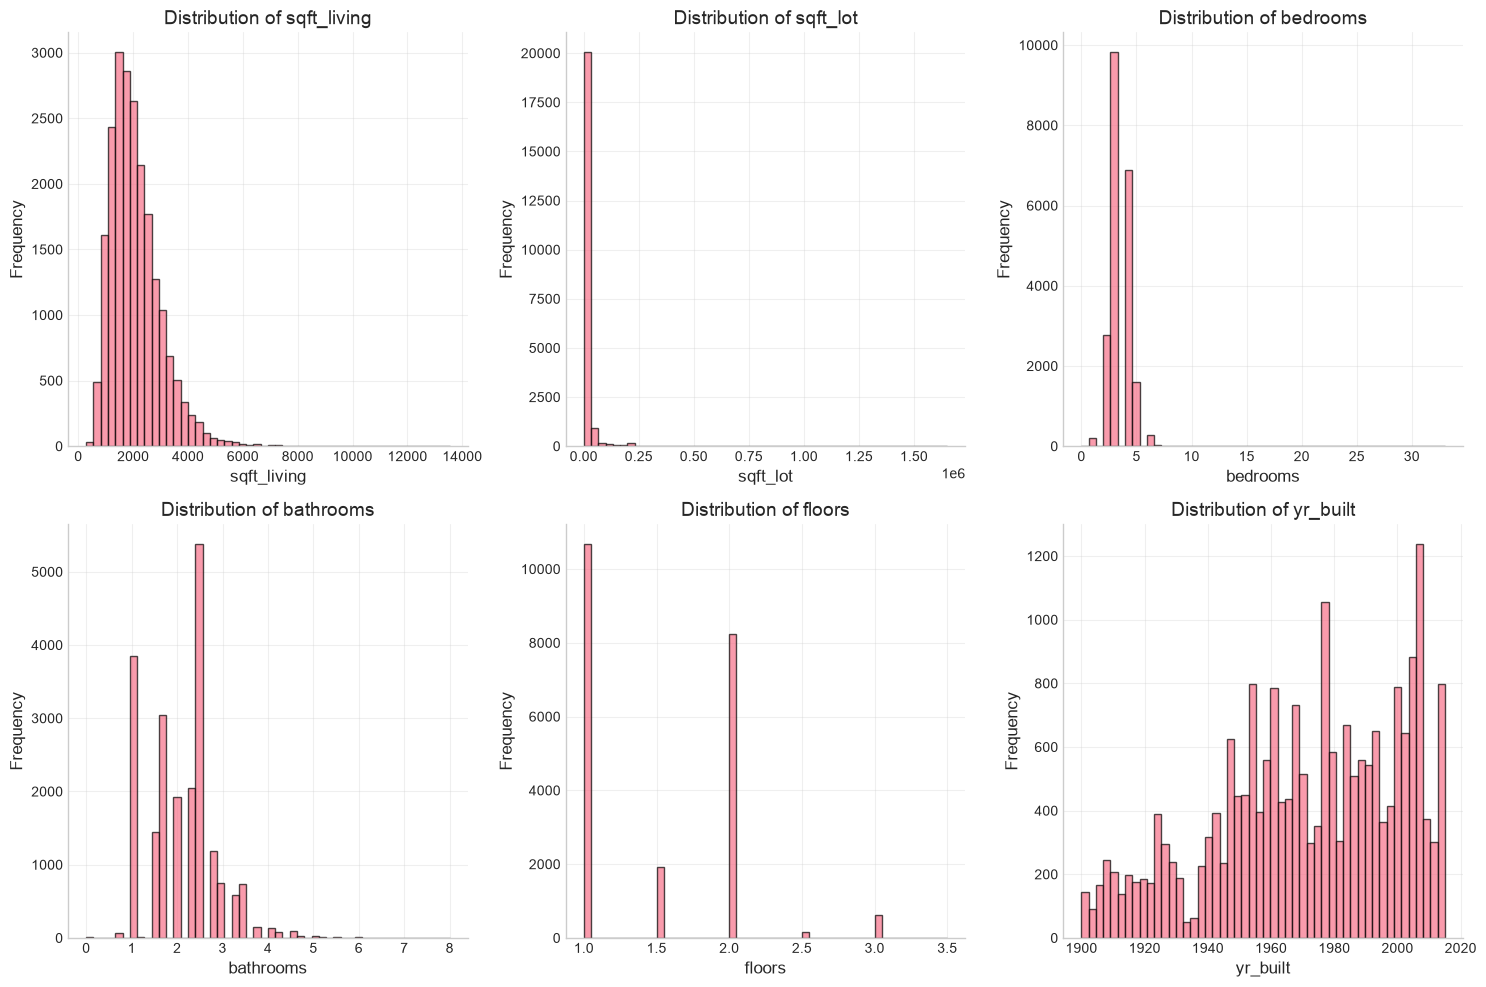

In [4]:
# 2. Key Feature Distributions
print("=== 2. Key Feature Distributions ===")
key_features = ['sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms', 'floors', 'yr_built']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, feat in enumerate(key_features):
    ax = axes[idx]
    ax.hist(df[feat].dropna(), bins=50, edgecolor='black', alpha=0.7)
    ax.set_title(f'Distribution of {feat}')
    ax.set_xlabel(feat)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

=== 3. Correlation Heatmap ===


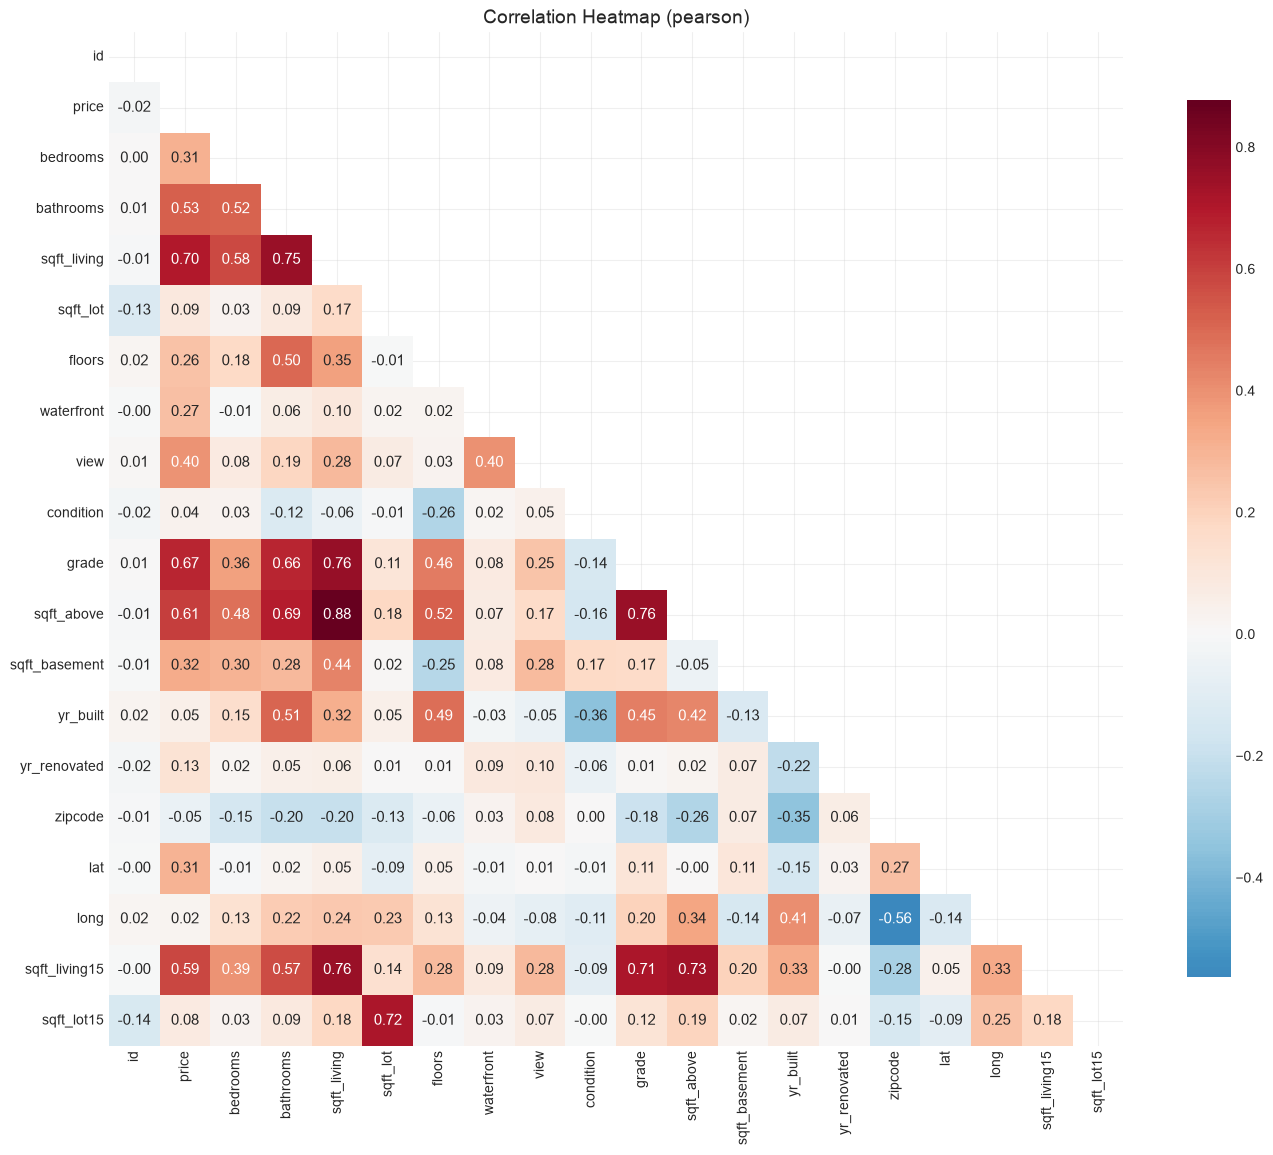

In [5]:
# 3. Correlation Heatmap
print("=== 3. Correlation Heatmap ===")
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
fig = plot_correlation_heatmap(df, numeric_cols)
plt.show()

=== 4. Price vs Key Features ===


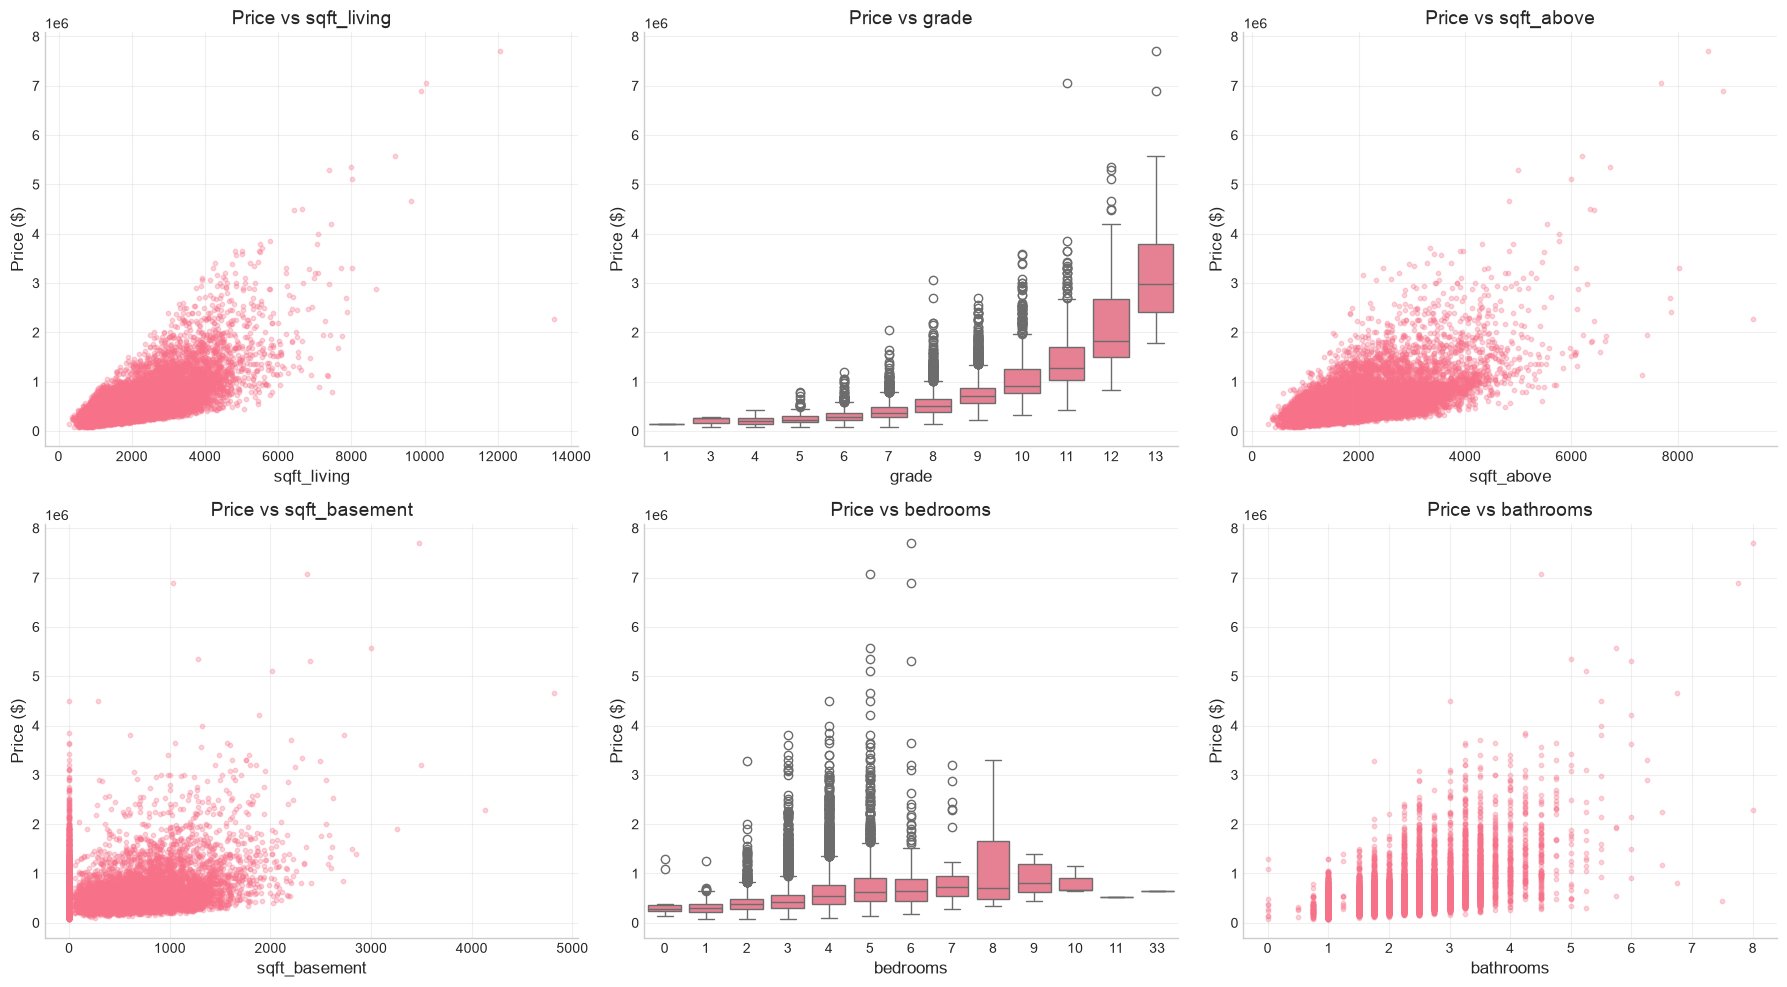

In [6]:
# 4. Price vs Key Features
print("=== 4. Price vs Key Features ===")
key_features = ['sqft_living', 'grade', 'sqft_above', 'sqft_basement', 'bedrooms', 'bathrooms']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, feat in enumerate(key_features):
    ax = axes[idx]
    if df[feat].nunique() > 15:
        ax.scatter(df[feat], df['price'], alpha=0.3, s=10)
    else:
        sns.boxplot(data=df, x=feat, y='price', ax=ax)
    ax.set_title(f'Price vs {feat}')
    ax.set_xlabel(feat)
    ax.set_ylabel('Price ($)')

plt.tight_layout()
plt.show()

=== 5. Categorical Analysis ===


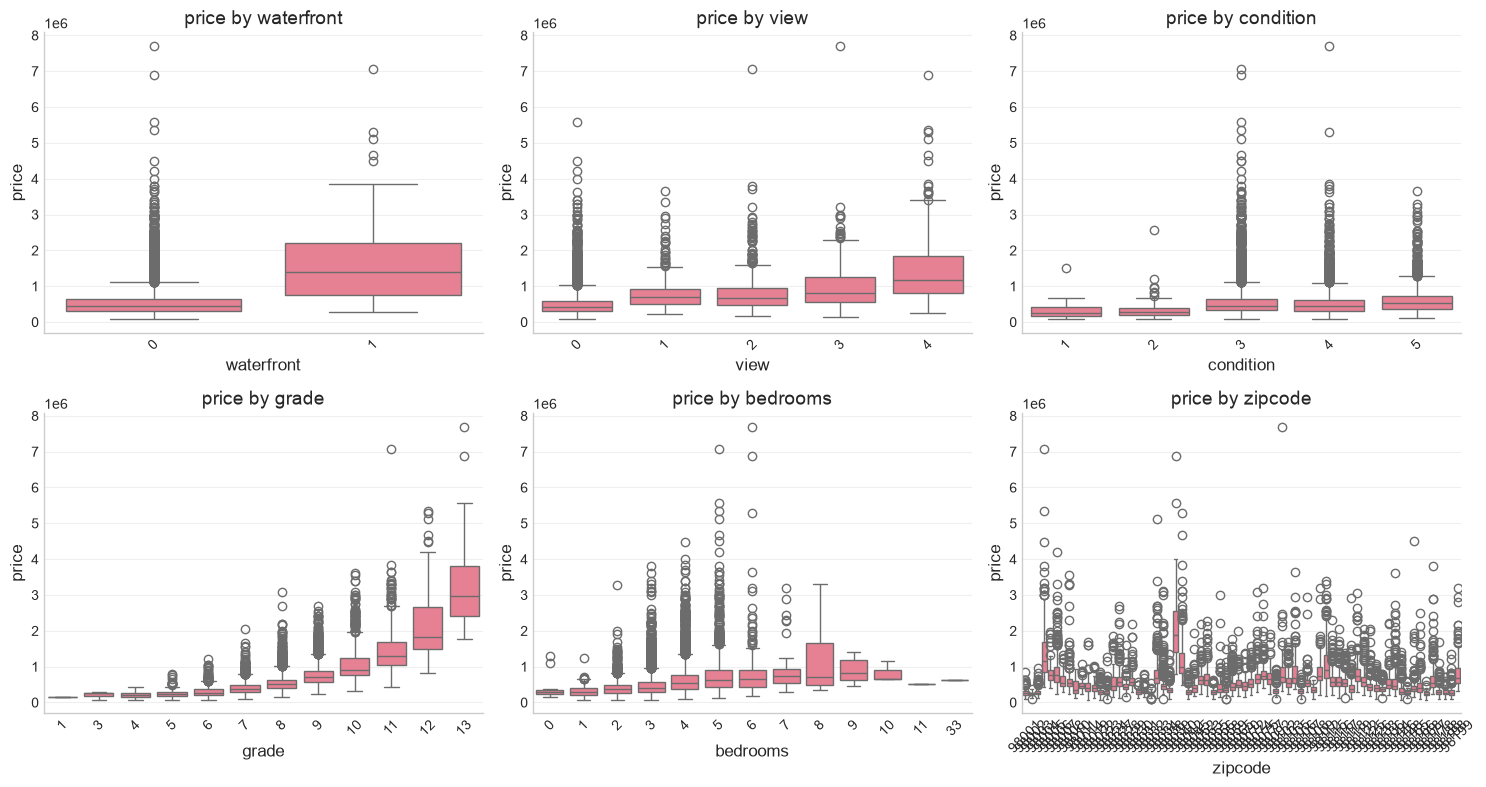

In [7]:
# 5. Categorical Analysis
print("=== 5. Categorical Analysis ===")
cat_features = ['waterfront', 'view', 'condition', 'grade', 'bedrooms', 'zipcode']
fig = plot_categorical_analysis(df, 'price', cat_features)
plt.show()

=== 6. Price per SqFt Analysis ===


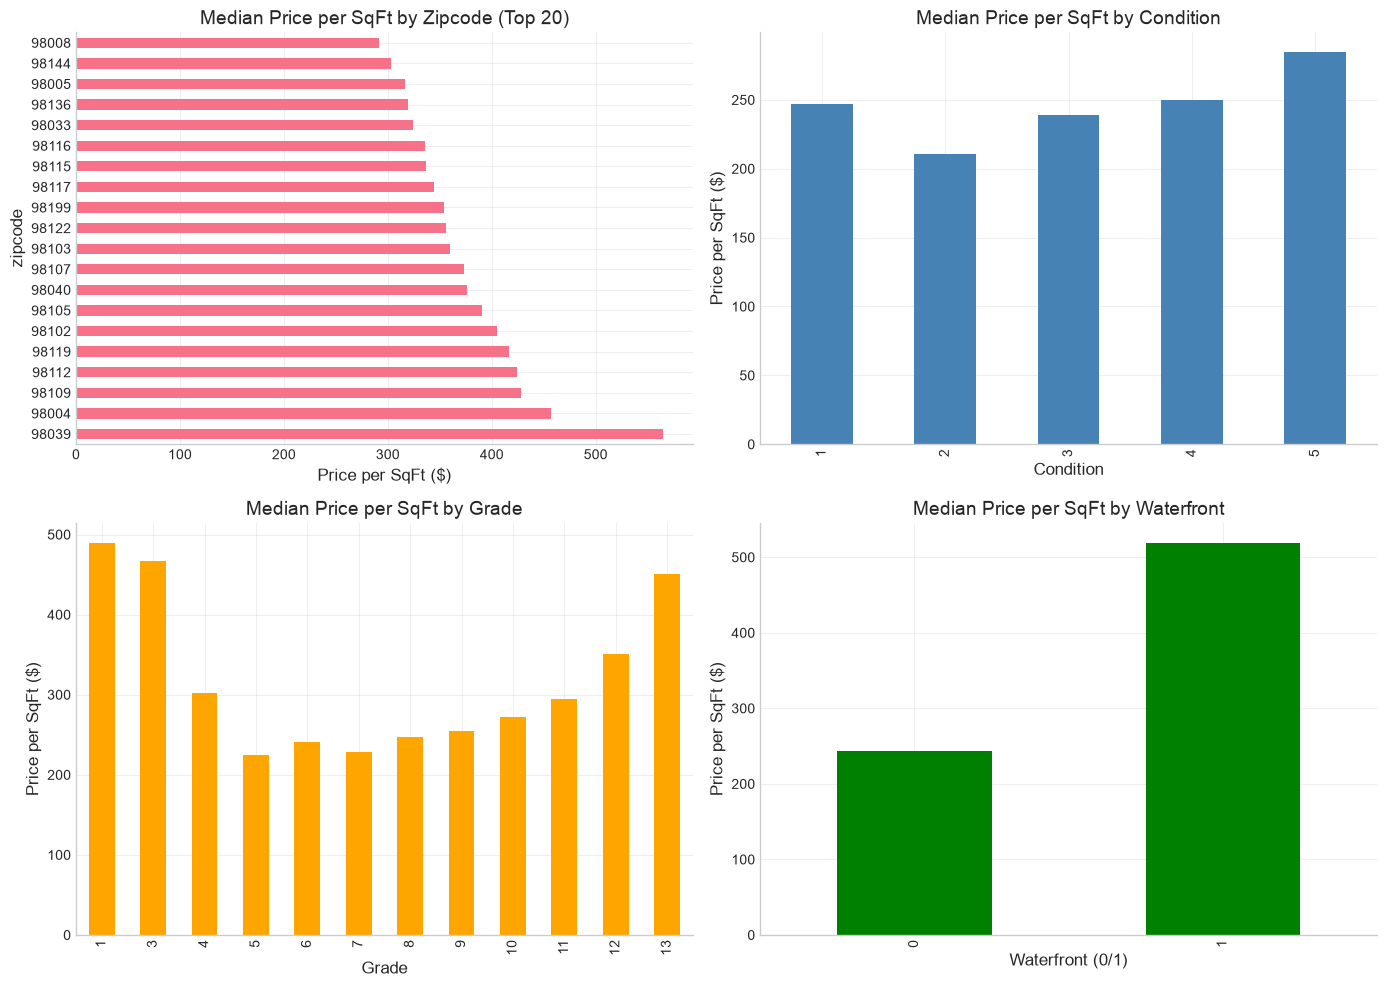

In [8]:
# 6. Price per SqFt Analysis
print("=== 6. Price per SqFt Analysis ===")
df['price_per_sqft'] = df['price'] / df['sqft_living']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# By zipcode (top 20)
ax = axes[0, 0]
zip_ppsqft = df.groupby('zipcode')['price_per_sqft'].median().sort_values(ascending=False).head(20)
zip_ppsqft.plot(kind='barh', ax=ax)
ax.set_title('Median Price per SqFt by Zipcode (Top 20)')
ax.set_xlabel('Price per SqFt ($)')

# By condition
ax = axes[0, 1]
cond_ppsqft = df.groupby('condition')['price_per_sqft'].median()
cond_ppsqft.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Median Price per SqFt by Condition')
ax.set_xlabel('Condition')
ax.set_ylabel('Price per SqFt ($)')

# By grade
ax = axes[1, 0]
grade_ppsqft = df.groupby('grade')['price_per_sqft'].median()
grade_ppsqft.plot(kind='bar', ax=ax, color='orange')
ax.set_title('Median Price per SqFt by Grade')
ax.set_xlabel('Grade')
ax.set_ylabel('Price per SqFt ($)')

# By waterfront
ax = axes[1, 1]
wf_ppsqft = df.groupby('waterfront')['price_per_sqft'].median()
wf_ppsqft.plot(kind='bar', ax=ax, color='green')
ax.set_title('Median Price per SqFt by Waterfront')
ax.set_xlabel('Waterfront (0/1)')
ax.set_ylabel('Price per SqFt ($)')

plt.tight_layout()
plt.show()

In [9]:
# 7. Geographic Price Distribution
print("=== 7. Geographic Price Distribution ===")
fig = plot_price_geographic(df)
fig.show()

# Save interactive HTML
fig.write_html(str(REPORTS_DIR / "geographic_prices.html"))

=== 7. Geographic Price Distribution ===


=== 8. Time Series Trends ===


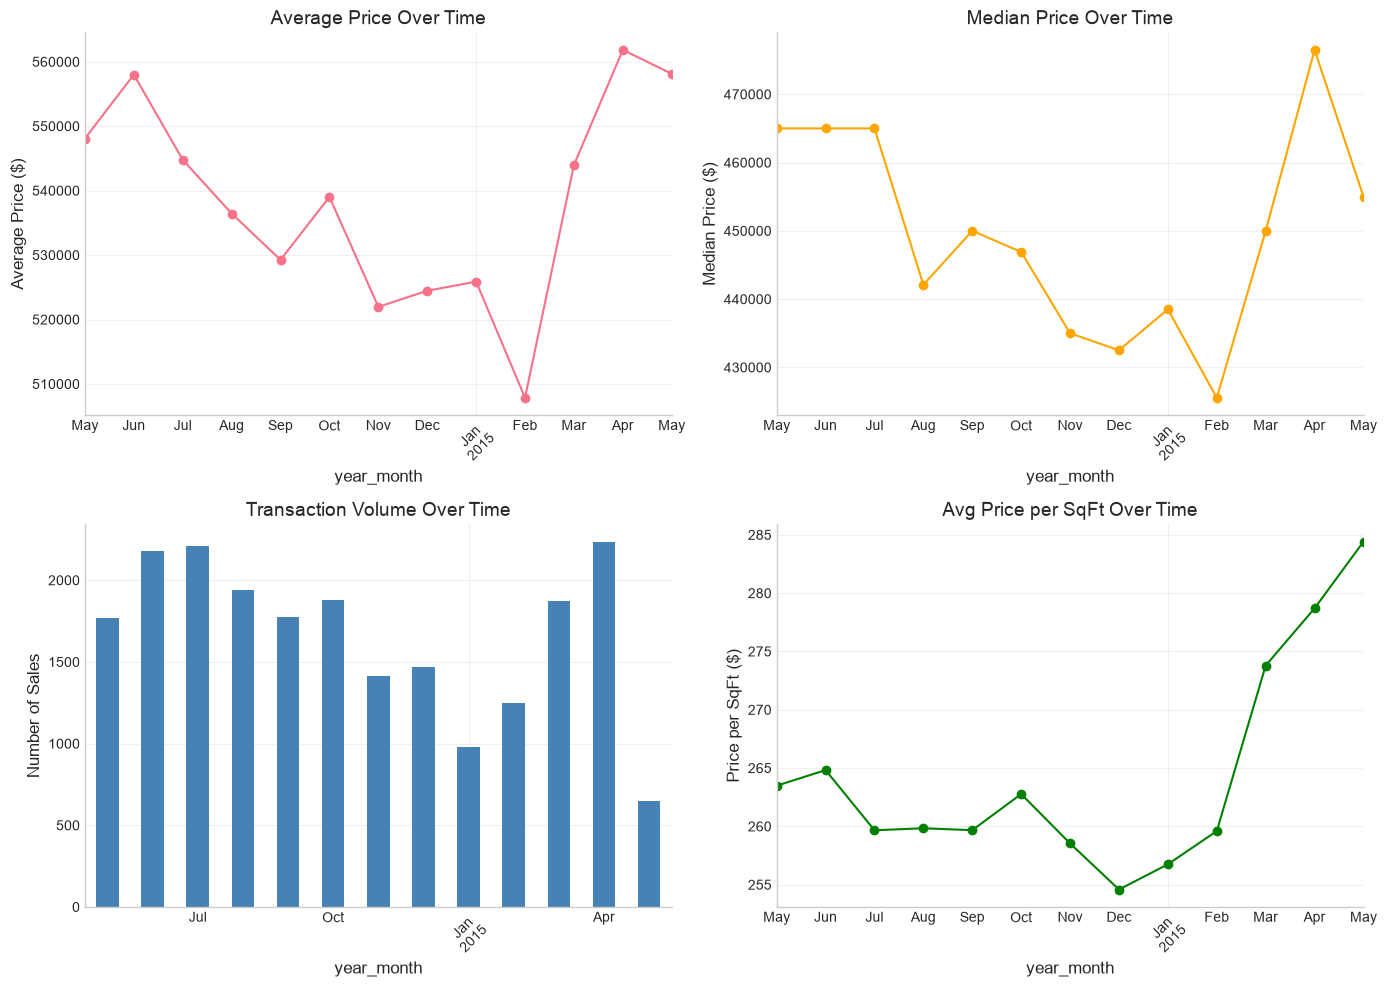

In [10]:
# 8. Time Series Trends
print("=== 8. Time Series Trends ===")
fig = plot_price_trends(df)
plt.show()

=== 9. Property Age Analysis ===


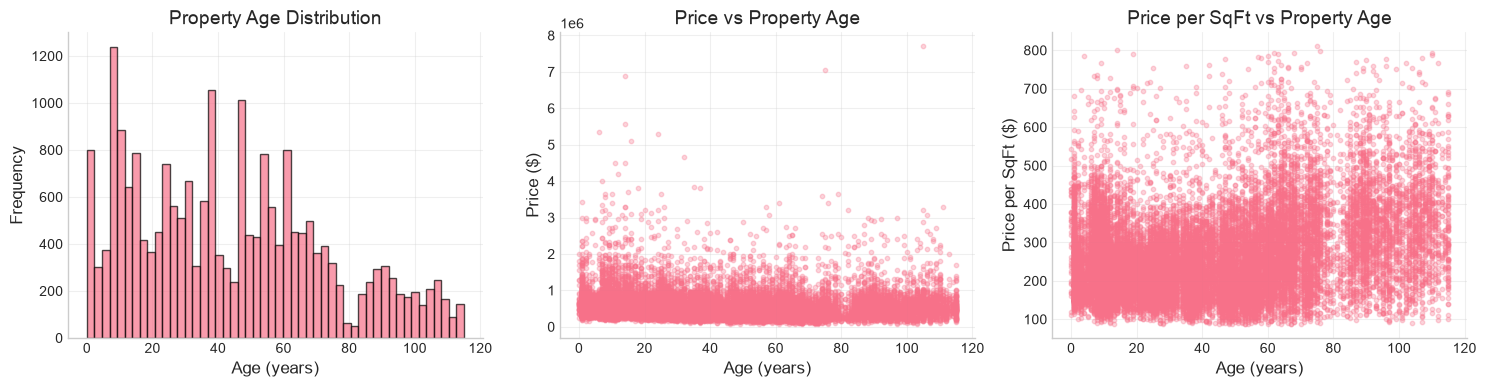

In [11]:
# 9. Property Age Analysis
print("=== 9. Property Age Analysis ===")
df['age'] = 2015 - df['yr_built']
df['age'] = df['age'].clip(lower=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Age distribution
axes[0].hist(df['age'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_title('Property Age Distribution')
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Frequency')

# Price vs Age
axes[1].scatter(df['age'], df['price'], alpha=0.3, s=10)
axes[1].set_title('Price vs Property Age')
axes[1].set_xlabel('Age (years)')
axes[1].set_ylabel('Price ($)')

# Price per sqft vs Age
axes[2].scatter(df['age'], df['price_per_sqft'], alpha=0.3, s=10)
axes[2].set_title('Price per SqFt vs Property Age')
axes[2].set_xlabel('Age (years)')
axes[2].set_ylabel('Price per SqFt ($)')

plt.tight_layout()
plt.show()

=== 10. Renovation Analysis ===
Renovated properties: 914 (4.2%)


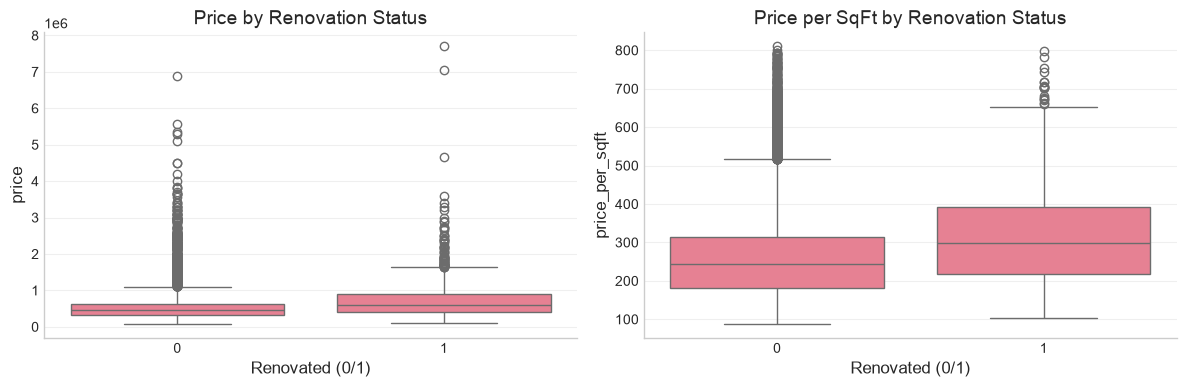

In [12]:
# 10. Renovation Analysis
print("=== 10. Renovation Analysis ===")
df['is_renovated'] = (df['yr_renovated'] > 0).astype(int)
print(f"Renovated properties: {df['is_renovated'].sum()} ({df['is_renovated'].mean()*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x='is_renovated', y='price', ax=axes[0])
axes[0].set_title('Price by Renovation Status')
axes[0].set_xlabel('Renovated (0/1)')

sns.boxplot(data=df, x='is_renovated', y='price_per_sqft', ax=axes[1])
axes[1].set_title('Price per SqFt by Renovation Status')
axes[1].set_xlabel('Renovated (0/1)')

plt.tight_layout()
plt.show()

=== 11. Basement Analysis ===
Properties with basement: 8487 (39.3%)


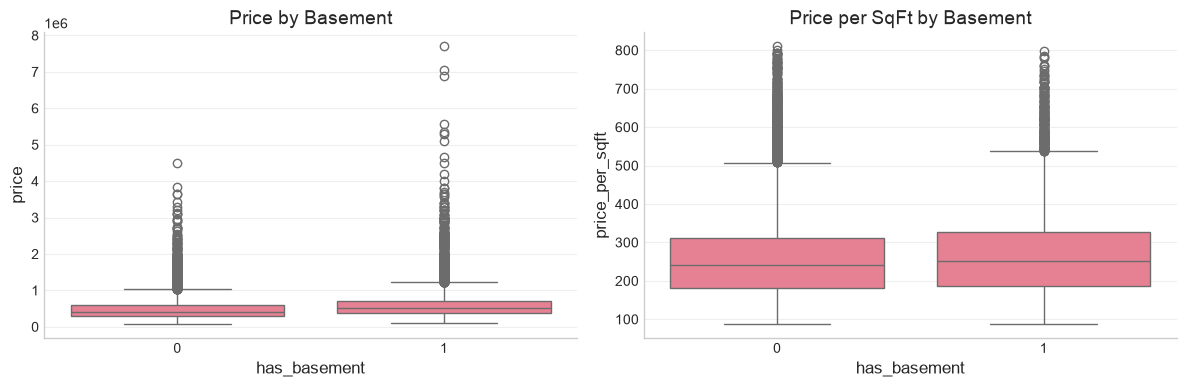

In [13]:
# 11. Basement Analysis
print("=== 11. Basement Analysis ===")
df['has_basement'] = (df['sqft_basement'] > 0).astype(int)
print(f"Properties with basement: {df['has_basement'].sum()} ({df['has_basement'].mean()*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x='has_basement', y='price', ax=axes[0])
axes[0].set_title('Price by Basement')

sns.boxplot(data=df, x='has_basement', y='price_per_sqft', ax=axes[1])
axes[1].set_title('Price per SqFt by Basement')

plt.tight_layout()
plt.show()

In [14]:
# 12. Comprehensive EDA Dashboard
print("=== 12. Creating Comprehensive EDA Dashboard ===")
figs = create_eda_dashboard(df, target='price', save_dir=REPORTS_DIR / "figures")
print("EDA Dashboard complete!")

=== 12. Creating Comprehensive EDA Dashboard ===
Plotting target distribution...


Plotting correlation heatmap...


Plotting key feature relationships...


Plotting categorical analysis...


Creating geographic plot...
EDA dashboard complete!
EDA Dashboard complete!


In [15]:
# 13. Generate EDA Report
print("=== 13. Generating EDA Report ===")

report_path = REPORTS_DIR / "eda_report.md"
with open(report_path, 'w') as f:
    f.write("# Exploratory Data Analysis Report\n\n")
    f.write(f"**Dataset:** King County House Sales ({df.shape[0]} properties)\n\n")
    
    f.write("## Key Findings\n\n")
    f.write("1. **Price Distribution**: Highly right-skewed, log-transform recommended\n")
    f.write("2. **Strongest Correlations**: sqft_living (0.70), grade (0.67), sqft_above (0.61)\n")
    f.write("3. **Waterfront Premium**: Waterfront properties command significant premium\n")
    f.write("4. **Grade Impact**: Property grade strongly correlates with price per sqft\n")
    f.write("5. **Geographic Variation**: Significant price variation across zipcodes\n")
    f.write("6. **Age Effect**: Newer properties generally command higher prices\n\n")
    
    f.write("## Price Statistics\n\n")
    f.write(f"- Mean: ${df['price'].mean():,.0f}\n")
    f.write(f"- Median: ${df['price'].median():,.0f}\n")
    f.write(f"- Std: ${df['price'].std():,.0f}\n")
    f.write(f"- Min: ${df['price'].min():,.0f}\n")
    f.write(f"- Max: ${df['price'].max():,.0f}\n\n")
    
    f.write("## Top Correlations with Price\n\n")
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    corrs = df[numeric_cols].corr()['price'].drop('price').sort_values(key=abs, ascending=False)
    f.write(corrs.head(10).to_markdown())
    f.write("\n\n")
    
    f.write("## Price per SqFt by Category\n\n")
    f.write(f"- Waterfront: ${df[df['waterfront']==1]['price_per_sqft'].median():,.0f} vs ${df[df['waterfront']==0]['price_per_sqft'].median():,.0f}\n")
    f.write(f"- Has Basement: ${df[df['has_basement']==1]['price_per_sqft'].median():,.0f} vs ${df[df['has_basement']==0]['price_per_sqft'].median():,.0f}\n")
    f.write(f"- Renovated: ${df[df['is_renovated']==1]['price_per_sqft'].median():,.0f} vs ${df[df['is_renovated']==0]['price_per_sqft'].median():,.0f}\n")

print(f"EDA Report saved to: {report_path}")

=== 13. Generating EDA Report ===


EDA Report saved to: /Users/premkumarreddy/projects/real estate/notebooks/../reports/eda_report.md
